# EDAV Course-End Project
## Electric Vehicle Charging Station Usage Analysis

**Department:** Information Technology  
**Course:** Exploratory Data Analysis and Visualization (EDAV)  
**Dataset:** `EVChargingStationUsage.csv`

### Objective
Analyze electric vehicle charging-session data using NumPy, Pandas, Matplotlib, and Seaborn. The project explores energy usage across port types and stations, prepares the dataset for analysis, summarizes charging activity, and visualizes usage patterns.

### Project workflow
1. Inspect and clean the dataset.
2. Perform numerical analysis with NumPy.
3. Analyze station and port-type patterns with Pandas.
4. Group charging sessions to calculate descriptive statistics.
5. Visualize results and write conclusions based on the output.

> **Important:** Run the notebook from top to bottom. Conclusions should be based on the values and charts produced by your own run; do not assume results before running the code.


## Environment Setup

### Concept Explanation
NumPy supports numerical calculations, Pandas handles tabular data, Matplotlib creates charts, and Seaborn helps display heatmaps. The code below imports these libraries and loads the CSV file.

### Code Implementation
If you are using Google Colab, upload `EVChargingStationUsage.csv` when prompted. If the file is already in the current folder or at `/content/EVChargingStationUsage.csv`, the notebook will use it.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make charts easier to read
sns.set_theme(style="whitegrid")

file_path = "/content/EVChargingStationUsage.csv"

if not os.path.exists(file_path):
    local_path = "EVChargingStationUsage.csv"
    if os.path.exists(local_path):
        file_path = local_path
    else:
        try:
            from google.colab import files
            uploaded = files.upload()
            file_path = next(iter(uploaded))
        except ImportError:
            raise FileNotFoundError(
                "Place EVChargingStationUsage.csv in the notebook folder, "
                "or upload it when using Google Colab."
            )

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Number of rows and columns: (259415, 33)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


## Initial Dataset Inspection

### Concept Explanation
Before analysis, inspect the columns, data types, missing values, and duplicate rows. This helps identify data-quality issues and decide what cleaning is appropriate.

### Code Implementation


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values in each column (top 15):")
display(df.isnull().sum().sort_values(ascending=False).head(15).to_frame("Missing Values"))

print("\nNumber of completely duplicated rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe(include="number").T)


Column names:
['Station Name', 'MAC Address', 'Org Name', 'Start Date', 'Start Time Zone', 'End Date', 'End Time Zone', 'Transaction Date (Pacific Time)', 'Total Duration (hh:mm:ss)', 'Charging Time (hh:mm:ss)', 'Energy (kWh)', 'GHG Savings (kg)', 'Gasoline Savings (gallons)', 'Port Type', 'Port Number', 'Plug Type', 'EVSE ID', 'Address 1', 'City', 'State/Province', 'Postal Code', 'Country', 'Latitude', 'Longitude', 'Currency', 'Fee', 'Ended By', 'Plug In Event Id', 'Driver Postal Code', 'User ID', 'County', 'System S/N', 'Model Number']

Data types:


,Data Type
Station Name,object
MAC Address,object
Org Name,object
Start Date,object
Start Time Zone,object
End Date,object
End Time Zone,object
Transaction Date (Pacific Time),object
Total Duration (hh:mm:ss),object
Charging Time (hh:mm:ss),object



Missing values in each column (top 15):


,Missing Values
County,84665
System S/N,78948
EVSE ID,78948
Model Number,78948
Driver Postal Code,8402
User ID,7677
Currency,1788
Ended By,248
Transaction Date (Pacific Time),209
Port Type,9



Number of completely duplicated rows: 4

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Energy (kWh),259415.0,8.544277e+00,7.185462e+00,1.000000e-02,3.784000e+00,6.868634e+00,1.145834e+01,9.736000e+01
GHG Savings (kg),259415.0,3.588596e+00,3.017894e+00,4.000000e-03,1.589000e+00,2.885000e+00,4.813000e+00,4.089100e+01
Gasoline Savings (gallons),259415.0,1.072306e+00,9.017761e-01,1.000000e-03,4.750000e-01,8.620000e-01,1.438000e+00,1.221900e+01
Port Number,259415.0,1.591627e+00,4.915337e-01,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00
EVSE ID,180467.0,1.462973e+05,2.429677e+05,3.792000e+03,4.358300e+04,1.074270e+05,1.745590e+05,5.535441e+06
Postal Code,259415.0,9.430232e+04,1.941657e+00,9.430100e+04,9.430100e+04,9.430100e+04,9.430300e+04,9.430600e+04
Latitude,259415.0,3.743956e+01,9.621170e-03,3.742210e+01,3.742832e+01,3.744449e+01,3.744661e+01,3.744938e+01
Longitude,259415.0,-1.221513e+02,1.538203e-02,-1.221632e+02,-1.221622e+02,-1.221583e+02,-1.221457e+02,-1.221125e+02
Fee,259415.0,1.097481e+00,1.934408e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.640000e+00,8.456000e+01
Plug In Event Id,259415.0,1.188685e+08,4.057750e+08,1.000000e+00,1.573000e+03,3.573000e+03,6.340000e+03,1.609436e+09


# Q1. Apply NumPy to calculate average, minimum, and maximum energy consumed by port type [CO1, BL3]

### Concept Explanation
NumPy provides functions such as `mean()`, `min()`, and `max()` for numerical summaries. Here, the energy consumed in each charging session is analyzed separately for each port type. Missing or invalid energy values are excluded from this calculation.

### Code Implementation


In [4]:
# Convert energy values to numeric; values that cannot be converted become missing
energy_numeric = pd.to_numeric(df["Energy (kWh)"], errors="coerce")

# Use the port type column to compare charging equipment categories
port_col = "Port Type"
q1_data = pd.DataFrame({
    "Port Type": df[port_col].fillna("Unknown"),
    "Energy (kWh)": energy_numeric
}).dropna(subset=["Energy (kWh)"])

q1_rows = []
for port_type, group in q1_data.groupby("Port Type"):
    values = group["Energy (kWh)"].to_numpy(dtype=float)
    if len(values) > 0:
        q1_rows.append({
            "Port Type": port_type,
            "Sessions with Energy Data": len(values),
            "Average Energy (kWh)": np.mean(values),
            "Minimum Energy (kWh)": np.min(values),
            "Maximum Energy (kWh)": np.max(values)
        })

q1_stats = pd.DataFrame(q1_rows).sort_values("Average Energy (kWh)", ascending=False)
display(q1_stats.round(2))


,Port Type,Sessions with Energy Data,Average Energy (kWh),Minimum Energy (kWh),Maximum Energy (kWh)
1,Level 2,254727,8.64,0.01,97.36
2,Unknown,9,6.60,1.73,29.65
0,Level 1,4679,3.07,0.01,26.54


### Conclusion / Insight
Use the table above to identify which port type has the highest average energy per session and which has the lowest. The minimum and maximum values show the range of energy recorded for each port type. These statistics describe the dataset; they do not by themselves prove why the differences occur.


# Q2. Use Pandas to analyze how charging station and port type relate to energy consumption [CO2, BL4]

### Concept Explanation
Pandas `groupby()` and aggregation functions help compare categories. In this question, calculate the number of sessions and average/total energy for each station and port type. Total energy reflects the combined energy recorded across sessions, while average energy compares typical session usage.

### Code Implementation


In [5]:
work = df.copy()
work["Energy (kWh)"] = pd.to_numeric(work["Energy (kWh)"], errors="coerce")
work["Station Name"] = work["Station Name"].fillna("Unknown Station")
work["Port Type"] = work["Port Type"].fillna("Unknown")

station_port_stats = (
    work.dropna(subset=["Energy (kWh)"])
        .groupby(["Station Name", "Port Type"], dropna=False)
        .agg(
            Number_of_Sessions=("Energy (kWh)", "size"),
            Total_Energy_kWh=("Energy (kWh)", "sum"),
            Average_Energy_kWh=("Energy (kWh)", "mean")
        )
        .reset_index()
        .sort_values("Total_Energy_kWh", ascending=False)
)

print("Top 10 station and port-type combinations by total energy:")
display(station_port_stats.head(10).round(2))

print("\nOverall energy summary by port type:")
port_summary = (
    work.dropna(subset=["Energy (kWh)"])
        .groupby("Port Type")
        .agg(
            Number_of_Sessions=("Energy (kWh)", "size"),
            Total_Energy_kWh=("Energy (kWh)", "sum"),
            Average_Energy_kWh=("Energy (kWh)", "mean")
        )
        .sort_values("Total_Energy_kWh", ascending=False)
)
display(port_summary.round(2))


Top 10 station and port-type combinations by total energy:


,Station Name,Port Type,Number_of_Sessions,Total_Energy_kWh,Average_Energy_kWh
19,PALO ALTO CA / HAMILTON #2,Level 2,23460,190952.23,8.14
56,PALO ALTO CA / WEBSTER #1,Level 2,14432,139068.86,9.64
57,PALO ALTO CA / WEBSTER #2,Level 2,12669,125795.49,9.93
16,PALO ALTO CA / HAMILTON #1,Level 2,14372,112248.04,7.81
25,PALO ALTO CA / HIGH #4,Level 2,13057,109421.06,8.38
4,PALO ALTO CA / BRYANT #2,Level 2,13004,103081.84,7.93
58,PALO ALTO CA / WEBSTER #3,Level 2,10484,98629.66,9.41
21,PALO ALTO CA / HIGH #1,Level 2,10756,98433.05,9.15
2,PALO ALTO CA / BRYANT #1,Level 2,11925,97196.66,8.15
52,PALO ALTO CA / TED THOMPSON #1,Level 2,9814,91167.89,9.29



Overall energy summary by port type:


,Number_of_Sessions,Total_Energy_kWh,Average_Energy_kWh
Port Type,,,
Level 2,254727,2202106.38,8.64
Level 1,4679,14347.85,3.07
Unknown,9,59.37,6.60


### Conclusion / Insight
Review the output to determine which station/port-type combinations contribute the most recorded energy and which port type has the highest average session energy. A high total may be caused by many sessions, high energy per session, or both. The number of sessions should therefore be considered alongside total energy.


# Q3. Handle missing values and prepare a clean dataset [CO3, BL3]

### Concept Explanation
Missing values and inconsistent data types can affect calculations. Convert date and numeric columns to their correct types, inspect missingness, and remove exact duplicate rows. For analysis-specific fields, keep records with missing values in unrelated columns rather than deleting whole rows unnecessarily. Missing energy values are excluded only from energy-based calculations.

### Code Implementation


In [6]:
df_clean = df.copy()

# Convert date fields to datetime
for col in ["Start Date", "End Date", "Transaction Date (Pacific Time)"]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

# Convert numeric fields safely
numeric_cols = [
    "Energy (kWh)", "GHG Savings (kg)", "Gasoline Savings (gallons)",
    "Latitude", "Longitude", "Fee", "Port Number"
]
for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

rows_before = len(df_clean)
duplicates_before = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

print("Rows before removing exact duplicates:", rows_before)
print("Exact duplicate rows found:", duplicates_before)
print("Rows after removing exact duplicates:", len(df_clean))

key_columns = ["Start Date", "Energy (kWh)", "Station Name"]
print("\nMissing values in key analysis columns:")
display(df_clean[key_columns].isnull().sum().to_frame("Missing Values"))

print("\nData types after conversion:")
display(df_clean.dtypes.to_frame("Data Type"))

print("\nCleaned dataset preview:")
display(df_clean.head())


Rows before removing exact duplicates: 259415
Exact duplicate rows found: 4
Rows after removing exact duplicates: 259411

Missing values in key analysis columns:


,Missing Values
Start Date,0
Energy (kWh),0
Station Name,0



Data types after conversion:


,Data Type
Station Name,object
MAC Address,object
Org Name,object
Start Date,datetime64[ns]
Start Time Zone,object
End Date,datetime64[ns]
End Time Zone,object
Transaction Date (Pacific Time),datetime64[ns]
Total Duration (hh:mm:ss),object
Charging Time (hh:mm:ss),object



Cleaned dataset preview:


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 00:00:00,PDT,2011-07-30 00:02:00,PDT,2011-07-30 00:02:00,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 08:16:00,PDT,2011-07-30 12:34:00,PDT,2011-07-30 12:34:00,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 14:51:00,PDT,2011-07-30 16:55:00,PDT,2011-07-30 16:55:00,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 18:51:00,PDT,2011-07-30 20:03:00,PDT,2011-07-30 20:03:00,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


In [15]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Conclusion / Insight
Compare the row counts before and after duplicate removal to see how many exact duplicate rows were present. The missing-value table identifies which key fields need care in later analysis. Missing values are not automatically replaced with zero because zero energy and unknown energy are different meanings.


# Q4. Group charging sessions by station and date to compute descriptive statistics [CO4, BL4]

### Concept Explanation
Grouping data can reveal how charging activity differs between stations and over time. This question calculates session counts, total energy, and average energy for each station, and summarizes charging activity by calendar date using the transaction date.

### Code Implementation


In [12]:
# Station-level descriptive statistics
station_activity = (
    df_clean.dropna(subset=["Energy (kWh)"]).groupby("Station Name").agg(Number_of_Sessions=("Energy (kWh)", "size"),
            Total_Energy_kWh=("Energy (kWh)", "sum"),
            Average_Energy_kWh=("Energy (kWh)", "mean")).sort_values("Number_of_Sessions", ascending=False))

print("Top 10 stations by number of sessions with valid energy data:")
display(station_activity.head(10).round(2))

# Daily activity summary
date_col = "Transaction Date (Pacific Time)"
if date_col in df_clean.columns:
    daily_data = df_clean.dropna(subset=[date_col]).copy()
    daily_data["Transaction Date"] = daily_data[date_col].dt.date
    daily_activity = (
        daily_data.groupby("Transaction Date")
        .agg(
            Number_of_Sessions=("Transaction Date", "size"),
            Total_Energy_kWh=("Energy (kWh)", "sum"),
            Average_Energy_kWh=("Energy (kWh)", "mean")
        )
        .sort_index()
    )
    print("\nDaily charging activity (first 10 dates):")
    display(daily_activity.head(10).round(2))
else:
    print("Transaction date column was not found.")


Top 10 stations by number of sessions with valid energy data:


,Number_of_Sessions,Total_Energy_kWh,Average_Energy_kWh
Station Name,,,
PALO ALTO CA / HAMILTON #2,23721,191721.78,8.08
PALO ALTO CA / HAMILTON #1,14888,113730.92,7.64
PALO ALTO CA / WEBSTER #1,14432,139068.86,9.64
PALO ALTO CA / BRYANT #2,14388,107256.18,7.45
PALO ALTO CA / HIGH #4,13898,111875.65,8.05
PALO ALTO CA / BRYANT #1,13436,102254.89,7.61
PALO ALTO CA / WEBSTER #2,12669,125795.49,9.93
PALO ALTO CA / CAMBRIDGE #1,11163,80517.26,7.21
PALO ALTO CA / HIGH #1,10756,98433.05,9.15



Daily charging activity (first 10 dates):


,Number_of_Sessions,Total_Energy_kWh,Average_Energy_kWh
Transaction Date,,,
2011-07-29,1,6.25,6.25
2011-07-30,4,24.18,6.04
2011-07-31,4,42.01,10.50
2011-08-01,1,5.04,5.04
2011-08-02,3,16.21,5.40
2011-08-03,4,22.81,5.70
2011-08-04,5,33.80,6.76
2011-08-05,5,31.49,6.30
2011-08-06,7,69.27,9.90


### Conclusion / Insight
The station table identifies locations with the most charging sessions in the dataset. The daily summary helps show whether activity changes over the recorded dates. A station with the most sessions is not necessarily the station with the highest average energy per session.


# Q5. Create bar plots and heatmaps to visualize charging patterns [CO5, BL5]

### Concept Explanation
Charts make comparisons easier than raw tables. A bar plot compares total energy among the busiest stations. A heatmap displays average energy by station and hour, where date-time values are available. Axis labels, titles, and color scales are included for readability.

### Code Implementation


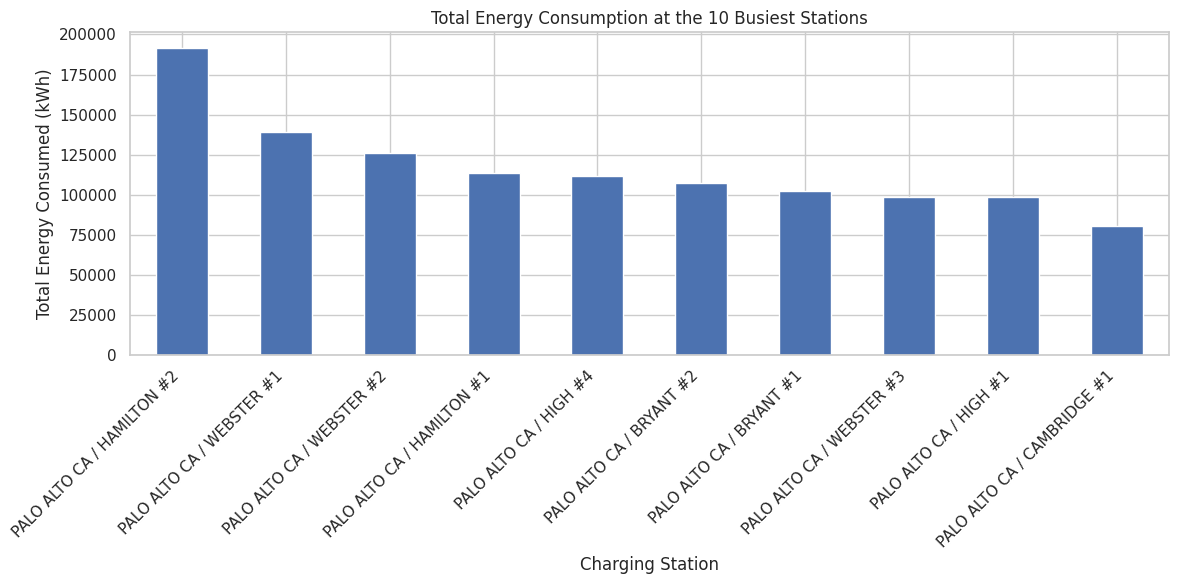

In [9]:
# Bar plot: total energy at the 10 stations with the most sessions
plot_data = df_clean.dropna(subset=["Energy (kWh)"]).copy()
top_stations_by_sessions = (
    plot_data.groupby("Station Name")["Energy (kWh)"]
    .size()
    .sort_values(ascending=False)
    .head(10)
    .index
)
top_station_energy = (
    plot_data[plot_data["Station Name"].isin(top_stations_by_sessions)]
    .groupby("Station Name")["Energy (kWh)"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
top_station_energy.plot(kind="bar")
plt.title("Total Energy Consumption at the 10 Busiest Stations")
plt.xlabel("Charging Station")
plt.ylabel("Total Energy Consumed (kWh)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


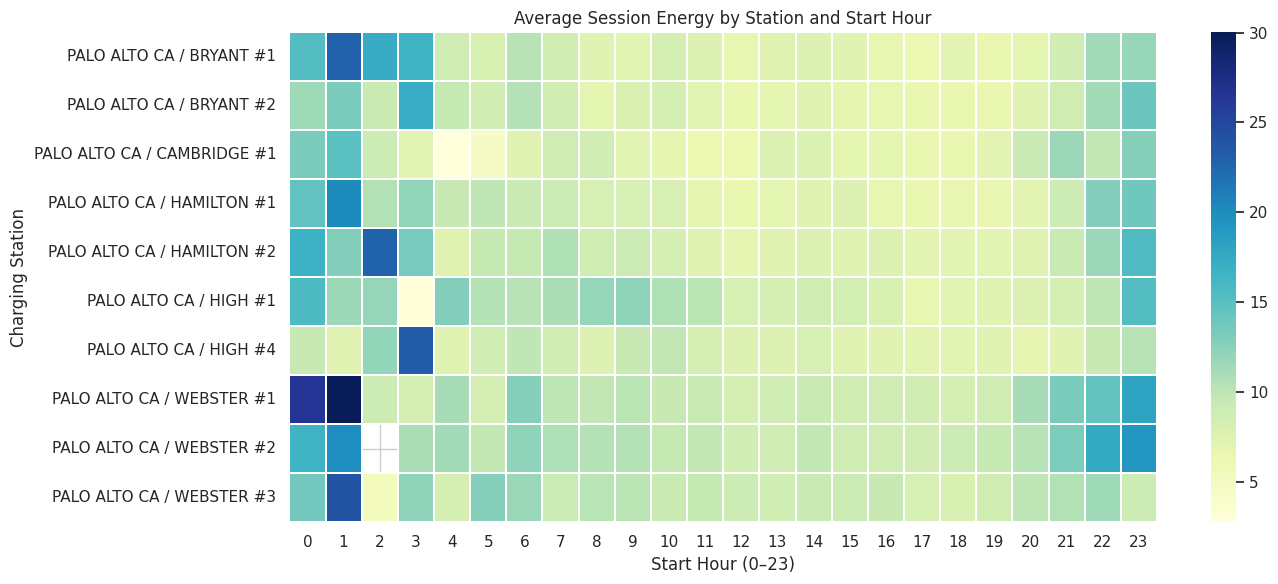

In [11]:
# Heatmap: average energy by station and hour of day
heatmap_data = df_clean.dropna(subset=["Start Date", "Energy (kWh)"]).copy()
heatmap_data["Start Hour"] = heatmap_data["Start Date"].dt.hour

# Limit to the 10 stations with the most sessions to keep the chart readable
top_heatmap_stations = (
    heatmap_data.groupby("Station Name").size()
    .sort_values(ascending=False).head(10).index
)
heatmap_data = heatmap_data[heatmap_data["Station Name"].isin(top_heatmap_stations)]

energy_heatmap = heatmap_data.pivot_table(
    index="Station Name",
    columns="Start Hour",
    values="Energy (kWh)",
    aggfunc="mean"
)

plt.figure(figsize=(14, 6))
sns.heatmap(energy_heatmap, cmap="YlGnBu", linewidths=0.3)
plt.title("Average Session Energy by Station and Start Hour")
plt.xlabel("Start Hour (0–23)")
plt.ylabel("Charging Station")
plt.tight_layout()
plt.show()



# Overall Project Conclusion

This project used NumPy and Pandas to summarize EV charging-session energy, compare stations and port types, inspect data quality, and group activity by station and date. Bar charts and a heatmap provided visual comparisons of recorded charging usage.

### Libraries used
- **NumPy:** numerical statistics.
- **Pandas:** data loading, cleaning, grouping, and aggregation.
- **Matplotlib:** bar chart visualization.
- **Seaborn:** heatmap visualization.


